In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Number of rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  floa

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# 1. Count missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check negative and zero quantities
print("\nNegative quantity rows:", (df["Quantity"] < 0).sum())
print("Zero quantity rows:", (df["Quantity"] == 0).sum())

# 4. Check negative and zero prices
print("\nNegative price rows:", (df["UnitPrice"] < 0).sum())
print("Zero price rows:", (df["UnitPrice"] == 0).sum())

# 5. Check cancelled invoices
print("\nCancelled invoice rows:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

# 6. Display examples of negative quantities
display(df[df["Quantity"] < 0].head())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Negative quantity rows: 10624
Zero quantity rows: 0

Negative price rows: 2
Zero price rows: 2515

Cancelled invoice rows: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [11]:
# Create a cleaned copy
df_clean = df.drop_duplicates().copy()

# Fill missing product descriptions
df_clean["Description"] = (
    df_clean["Description"].fillna("Unknown product")
)

# Keep missing CustomerID values as they are
# because we may still use these records for sales analysis

# Create a column for transaction value
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:",
      df_clean.duplicated().sum())

print("\nTotal revenue across all remaining records:",
      round(df_clean["Revenue"].sum(), 2))

Original dataset shape: (541909, 8)
Cleaned dataset shape: (536641, 9)

Missing values after cleaning:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
Revenue             0
dtype: int64

Duplicate rows after cleaning: 0

Total revenue across all remaining records: 9726006.95


In [12]:
# Exclude cancelled invoices
not_cancelled = ~df_clean["InvoiceNo"].astype(str).str.startswith("C")

# Select records suitable for positive-sales analysis
sales_df = df_clean[
    not_cancelled
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
].copy()

print("Sales dataset shape:", sales_df.shape)

print("\nTotal revenue:", round(sales_df["Revenue"].sum(), 2))
print("Total items sold:", sales_df["Quantity"].sum())
print("Unique invoices:", sales_df["InvoiceNo"].nunique())
print("Unique products:", sales_df["StockCode"].nunique())
print("Countries:", sales_df["Country"].nunique())

Sales dataset shape: (524878, 9)

Total revenue: 10642110.8
Total items sold: 5572420
Unique invoices: 19960
Unique products: 3922
Countries: 38


In [13]:
# Descriptive statistics for quantity
print("QUANTITY STATISTICS")
print("Mean:", sales_df["Quantity"].mean())
print("Median:", sales_df["Quantity"].median())
print("Mode:", sales_df["Quantity"].mode().tolist())
print("Standard deviation:", sales_df["Quantity"].std())
print("Variance:", sales_df["Quantity"].var())

# Descriptive statistics for unit price
print("\nUNIT PRICE STATISTICS")
print("Mean:", sales_df["UnitPrice"].mean())
print("Median:", sales_df["UnitPrice"].median())
print("Mode:", sales_df["UnitPrice"].mode().tolist())
print("Standard deviation:", sales_df["UnitPrice"].std())
print("Variance:", sales_df["UnitPrice"].var())

# Correlation between quantity and unit price
print("\nCorrelation:")
print(sales_df[["Quantity", "UnitPrice", "Revenue"]].corr())

QUANTITY STATISTICS
Mean: 10.616600429052085
Median: 4.0
Mode: [1]
Standard deviation: 156.28003072343193
Variance: 24423.448002916826

UNIT PRICE STATISTICS
Mean: 3.9225725673394582
Median: 2.08
Mode: [1.25]
Standard deviation: 36.093027531937864
Variance: 1302.7066364212246

Correlation:
           Quantity  UnitPrice   Revenue
Quantity   1.000000  -0.003788  0.907402
UnitPrice -0.003788   1.000000  0.137381
Revenue    0.907402   0.137381  1.000000


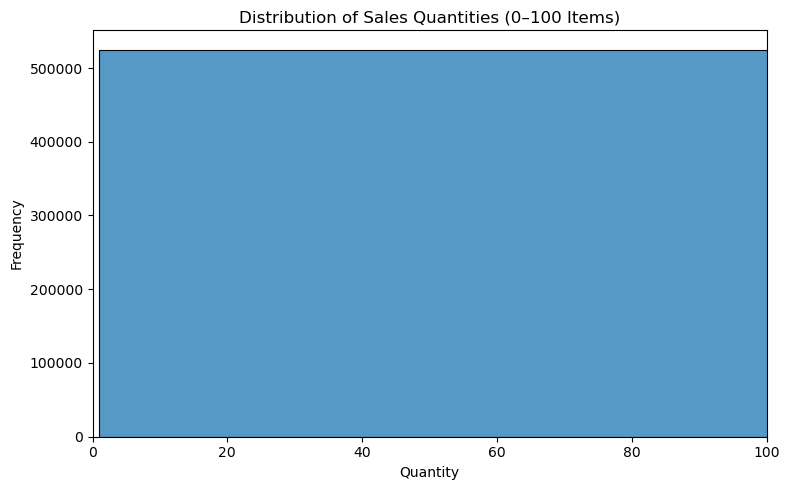

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(sales_df["Quantity"], bins=50)
plt.xlim(0, 100)
plt.title("Distribution of Sales Quantities (0–100 Items)")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

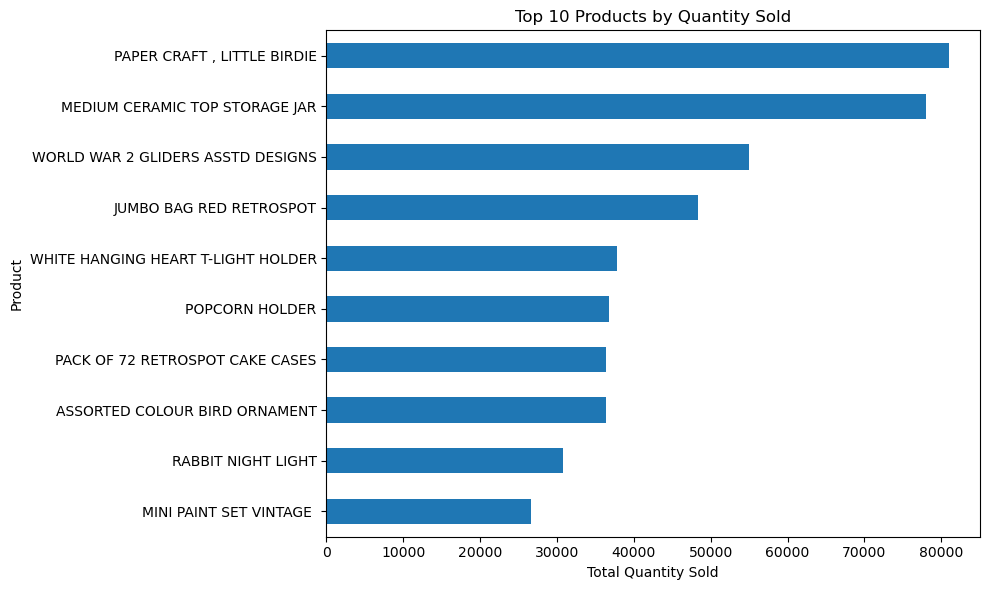

In [15]:
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

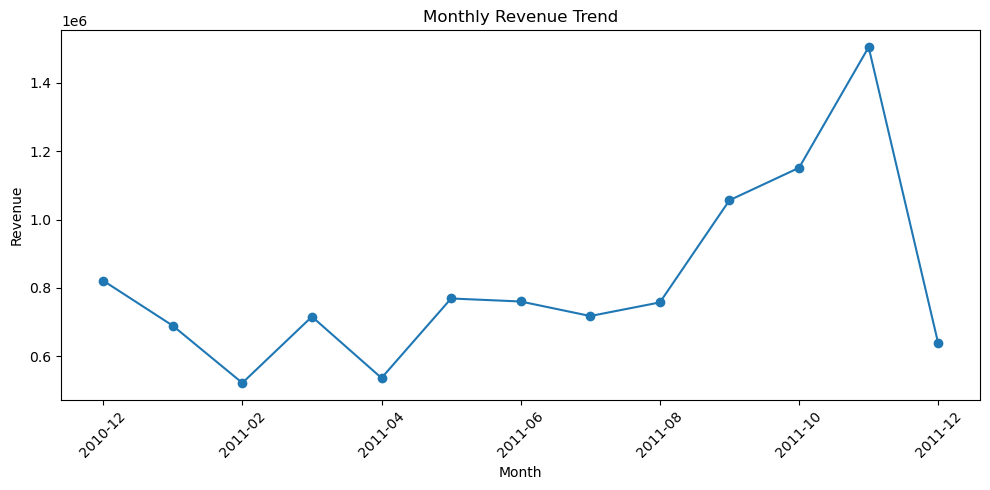

In [16]:
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M").astype(str)

monthly_revenue = sales_df.groupby("Month")["Revenue"].sum()

plt.figure(figsize=(10, 5))
monthly_revenue.plot(marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

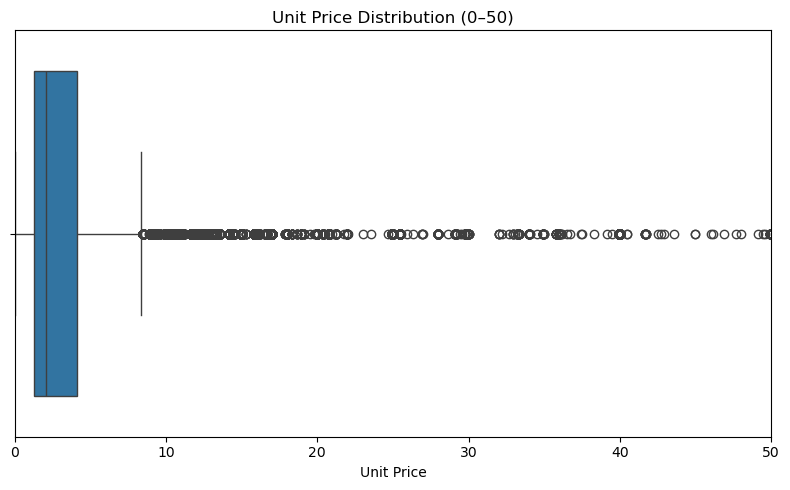

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=sales_df["UnitPrice"])
plt.xlim(0, 50)
plt.title("Unit Price Distribution (0–50)")
plt.xlabel("Unit Price")
plt.tight_layout()
plt.show()

In [18]:
# Top 5 countries by revenue
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 countries by revenue:")
display(country_revenue)

# Monthly revenue
print("\nMonthly revenue:")
display(monthly_revenue)

# Top 5 products by revenue
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("\nTop 5 products by revenue:")
display(product_revenue)

Top 5 countries by revenue:


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Name: Revenue, dtype: float64


Monthly revenue:


Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Name: Revenue, dtype: float64


Top 5 products by revenue:


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
Name: Revenue, dtype: float64